# A3 — Wide-and-deep architecture

Both branches receive the same four embeddings and six continuous features. The prediction is `MLP output + lambda × linear output`, where the MLP is the selected A1 architecture.


In [2]:
import copy
import json
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader

PART_A = Path.cwd()
if PART_A.name != "part-a":
    PART_A = PART_A / "part-a"
sys.path.append(str(PART_A / "src"))

from config import Config
from data import prepare_data
from model import PriceModel, WideAndDeepModel

A1_CONFIG = replace(Config(), hidden_width=256, embedding_dims=(4, 4, 4, 4))
A1_EPOCHS = 6
LAMBDAS = [0, 0.25, 0.5, 1, 2]
SEEDS = [42, 43, 44, 45, 46]
OUTPUT_DIR = PART_A / "outputs" / "a3"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

torch.set_num_threads(1)
torch.use_deterministic_algorithms(True, warn_only=True)


## Training functions

Use A1's Adam settings (learning rate 0.01, batch size 512). During lambda selection, early stopping uses at most 20 epochs, patience 4, and minimum improvement 1e-4. Final retraining uses the selected epoch count and does not access the test set until training finishes.


In [3]:
def make_model(data, seed, lambda_value=None):
    torch.manual_seed(seed)
    args = (data["cardinalities"], data["target_mean"], data["target_std"], A1_CONFIG)
    if lambda_value is None:
        return PriceModel(*args)
    return WideAndDeepModel(*args, lambda_value=lambda_value)


@torch.no_grad()
def evaluate(model, dataset):
    model.eval()
    predictions, targets = [], []
    for categorical, continuous, target in DataLoader(
        dataset, batch_size=A1_CONFIG.batch_size
    ):
        predictions.append(model.predict_price(categorical, continuous))
        targets.append(target)
    prediction = torch.cat(predictions)
    target = torch.cat(targets)
    residual_sum = (prediction - target).square().sum()
    total_sum = (target - target.mean()).square().sum()
    return (residual_sum / len(target)).sqrt().item(), (1 - residual_sum / total_sum).item()


def train_model(model, training_data, seed, epochs, validation_data=None):
    torch.manual_seed(seed)
    generator = torch.Generator().manual_seed(seed)
    loader = DataLoader(
        training_data, batch_size=A1_CONFIG.batch_size,
        shuffle=True, generator=generator,
    )
    optimiser = torch.optim.Adam(model.parameters(), lr=A1_CONFIG.learning_rate)
    loss_function = nn.MSELoss()
    history = []
    best_rmse = float("inf")
    best_epoch = epochs
    best_weights = None
    epochs_without_improvement = 0

    for epoch in range(1, epochs + 1):
        model.train()
        for categorical, continuous, target in loader:
            optimiser.zero_grad()
            standard_target = (target - model.target_mean) / model.target_std
            loss = loss_function(model(categorical, continuous), standard_target)
            loss.backward()
            optimiser.step()

        if validation_data is not None:
            validation_rmse, _ = evaluate(model, validation_data)
            history.append({"epoch": epoch, "validation_rmse": validation_rmse})
            if validation_rmse < best_rmse - A1_CONFIG.early_stopping_threshold:
                best_rmse = validation_rmse
                best_epoch = epoch
                best_weights = copy.deepcopy(model.state_dict())
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1
                if epochs_without_improvement == A1_CONFIG.early_stopping_patience:
                    break

    if validation_data is not None:
        model.load_state_dict(best_weights)
    return history, best_epoch, best_rmse


## Select lambda on validation data

Train on 2017–2020 and validate on 2021, fitting preprocessing on 2017–2020 only. Use seed 42 for every candidate and select the lowest best validation RMSE. Lambda 0 disables the linear branch and acts as a baseline check.


In [4]:
search_data = prepare_data(PART_A / "hdb_price_prediction.csv", A1_CONFIG)
search_results, histories = [], []
for lambda_value in LAMBDAS:
    print(f"Training lambda = {lambda_value}", flush=True)
    model = make_model(search_data, SEEDS[0], lambda_value)
    history, best_epoch, best_rmse = train_model(
        model, search_data["train"], SEEDS[0], A1_CONFIG.max_epochs,
        validation_data=search_data["validation"],
    )
    search_results.append({
        "lambda": lambda_value, "best_epoch": best_epoch,
        "validation_rmse": best_rmse, "epochs_run": len(history),
    })
    histories.extend({"lambda": lambda_value, **row} for row in history)
    print(f"Best epoch {best_epoch} | validation RMSE {best_rmse:,.2f}")

search_results = pd.DataFrame(search_results)
histories = pd.DataFrame(histories)
search_results.to_csv(OUTPUT_DIR / "lambda_search.csv", index=False)
histories.to_csv(OUTPUT_DIR / "validation_history.csv", index=False)
display(search_results.round({"validation_rmse": 2}))

best = search_results.loc[search_results["validation_rmse"].idxmin()]
best_lambda = float(best["lambda"])
selected_epochs = int(best["best_epoch"])
selection = {"lambda": best_lambda, "epochs": selected_epochs, "search_seed": SEEDS[0]}
(OUTPUT_DIR / "selection.json").write_text(json.dumps(selection, indent=2))
print(f"Selected lambda: {best_lambda}; retraining epochs: {selected_epochs}")


Training lambda = 0


Best epoch 6 | validation RMSE 58,656.77
Training lambda = 0.25


Best epoch 6 | validation RMSE 59,630.80
Training lambda = 0.5


Best epoch 6 | validation RMSE 58,764.72
Training lambda = 1


Best epoch 6 | validation RMSE 58,618.14
Training lambda = 2


Best epoch 3 | validation RMSE 57,771.09


,lambda,best_epoch,validation_rmse,epochs_run
0,0.00,6,58656.77,10
1,0.25,6,59630.80,10
2,0.50,6,58764.72,10
3,1.00,6,58618.14,10
4,2.00,3,57771.09,7


Selected lambda: 2.0; retraining epochs: 3


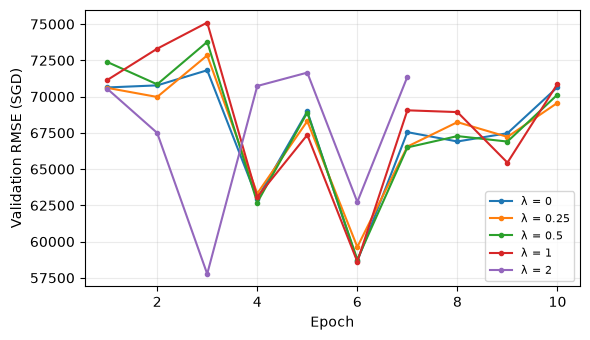

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for lambda_value in LAMBDAS:
    rows = histories[histories["lambda"] == lambda_value]
    ax.plot(rows["epoch"], rows["validation_rmse"], marker="o", markersize=3,
            label=f"λ = {lambda_value}")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation RMSE (SGD)")
ax.grid(alpha=0.25)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(PART_A / "a3_validation_rmse.png", dpi=200)
plt.show()


## Retrain and evaluate over five seeds

Refit preprocessing on 2017–2021. Train the selected wide-and-deep model for its best validation epoch count; reproduce the A1 baseline for its selected six epochs. These durations are fixed before any test evaluation. Each model is evaluated once on 2022, and seed-42 weights are saved for A4.


In [6]:
final_config = replace(A1_CONFIG, train_years=(2017, 2018, 2019, 2020, 2021))
final_data = prepare_data(PART_A / "hdb_price_prediction.csv", final_config)
print(f"Training rows: {len(final_data['train']):,}; test rows: {len(final_data['test']):,}")

results = []
for name, lambda_value, epochs in [
    ("Baseline", None, A1_EPOCHS),
    ("Wide-and-deep", best_lambda, selected_epochs),
]:
    for seed in SEEDS:
        model = make_model(final_data, seed, lambda_value)
        train_model(model, final_data["train"], seed, epochs)
        test_rmse, test_r2 = evaluate(model, final_data["test"])
        parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
        results.append({
            "model": name, "seed": seed, "epochs": epochs,
            "parameters": parameters, "test_rmse": test_rmse, "test_r2": test_r2,
        })
        if seed == SEEDS[0]:
            filename = "baseline_seed42.pt" if name == "Baseline" else "wide_deep_seed42.pt"
            torch.save(model.state_dict(), OUTPUT_DIR / filename)
        print(f"{name:13s} | seed {seed} | RMSE {test_rmse:,.2f} | R² {test_r2:.4f}")

results = pd.DataFrame(results)
results.to_csv(OUTPUT_DIR / "seed_results.csv", index=False)
display(results.round({"test_rmse": 2, "test_r2": 4}))


Training rows: 116,427; test rows: 26,702


Baseline      | seed 42 | RMSE 96,984.81 | R² 0.6755


Baseline      | seed 43 | RMSE 101,802.02 | R² 0.6425


Baseline      | seed 44 | RMSE 101,617.39 | R² 0.6438


Baseline      | seed 45 | RMSE 104,451.07 | R² 0.6236


...

Wide-and-deep | seed 43 | RMSE 106,320.02 | R² 0.6101


Wide-and-deep | seed 44 | RMSE 106,482.89 | R² 0.6089


Wide-and-deep | seed 45 | RMSE 108,541.01 | R² 0.5936


Wide-and-deep | seed 46 | RMSE 104,465.82 | R² 0.6235


,model,seed,epochs,parameters,test_rmse,test_r2
0,Baseline,42,6,7065,96984.81,0.6755
1,Baseline,43,6,7065,101802.02,0.6425
2,Baseline,44,6,7065,101617.39,0.6438
3,Baseline,45,6,7065,104451.07,0.6236
4,Baseline,46,6,7065,105691.07,0.6147
5,Wide-and-deep,42,3,7088,104790.52,0.6212
6,Wide-and-deep,43,3,7088,106320.02,0.6101
7,Wide-and-deep,44,3,7088,106482.89,0.6089
8,Wide-and-deep,45,3,7088,108541.01,0.5936
9,Wide-and-deep,46,3,7088,104465.82,0.6235


## Comparison with the baseline

Report mean and sample standard deviation (`ddof=1`) over the five seeds. Compare models at matched seeds; any difference in selected epoch counts is a confound when interpreting the architectural change.


In [7]:
model_names = ["Baseline", "Wide-and-deep"]
summary = results.groupby("model").agg(
    epochs=("epochs", "first"), parameters=("parameters", "first"),
    rmse_mean=("test_rmse", "mean"), rmse_sd=("test_rmse", "std"),
    r2_mean=("test_r2", "mean"), r2_sd=("test_r2", "std"),
).reindex(model_names)
summary.to_csv(OUTPUT_DIR / "summary.csv")
display(summary.round({"rmse_mean": 2, "rmse_sd": 2, "r2_mean": 4, "r2_sd": 4}))

paired_rmse = results.pivot(index="seed", columns="model", values="test_rmse")
difference = paired_rmse["Wide-and-deep"] - paired_rmse["Baseline"]
print(f"Mean RMSE change: {difference.mean():+,.2f} SGD")
print(f"Wide-and-deep has lower RMSE in {(difference < 0).sum()}/{len(SEEDS)} seeds")


,epochs,parameters,rmse_mean,rmse_sd,r2_mean,r2_sd
model,,,,,,
Baseline,6,7065,102109.27,3350.74,0.6400,0.0234
Wide-and-deep,3,7088,106120.05,1623.02,0.6114,0.0119


Mean RMSE change: +4,010.78 SGD
Wide-and-deep has lower RMSE in 1/5 seeds


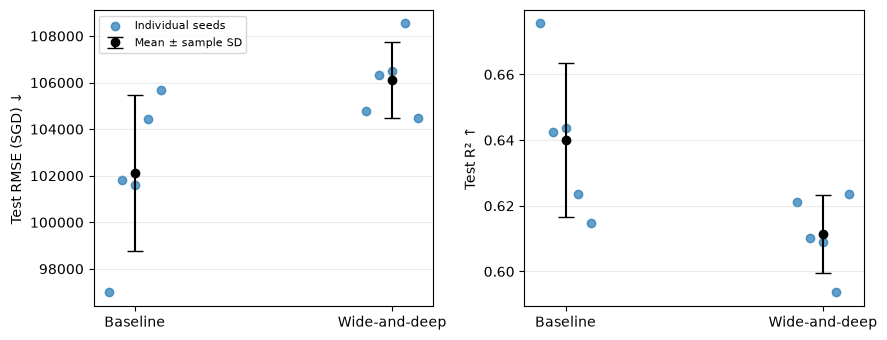

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
positions = np.arange(len(model_names))
offsets = np.linspace(-0.10, 0.10, len(SEEDS))
for ax, metric, mean_column, sd_column, ylabel in [
    (axes[0], "test_rmse", "rmse_mean", "rmse_sd", "Test RMSE (SGD) ↓"),
    (axes[1], "test_r2", "r2_mean", "r2_sd", "Test R² ↑"),
]:
    ax.errorbar(positions, summary[mean_column], yerr=summary[sd_column],
                fmt="o", color="black", capsize=6, label="Mean ± sample SD", zorder=3)
    for index, name in enumerate(model_names):
        values = results[results["model"] == name].set_index("seed").loc[SEEDS, metric]
        ax.scatter(index + offsets, values, color="tab:blue", alpha=0.7,
                   label="Individual seeds" if index == 0 else None)
    ax.set_xticks(positions, model_names)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.25)
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(PART_A / "a3_test_results.png", dpi=200)
plt.show()
